# 07 - Generalização e viés–variância

A capacidade de generalização é analisada por meio das diferenças entre treino e teste e de validação cruzada com cinco folds. O gap de desempenho é definido como desempenho no treino menos desempenho no teste.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
ROOT = Path.cwd().resolve()
if not (ROOT/'data').exists(): ROOT = ROOT.parent
assert (ROOT/'src').exists(), 'Abra o notebook a partir da pasta do projeto.'
sys.path.insert(0,str(ROOT))
TAB=ROOT/'reports'/'tables'; FIG=ROOT/'reports'/'figures'
META=json.loads((ROOT/'data/processed/metadata.json').read_text(encoding='utf-8'))
print('Projeto:', ROOT)

Projeto: C:\Users\Felipe Erik\Desktop\Trabalho2IA\final\student_career_ia


## Recalcular validação cruzada
Os modelos são avaliados em cinco folds do conjunto de treinamento. O conjunto de teste não participa dessa etapa.

In [2]:
import pickle
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score
from src.training import prepare
resultados_cv = []
for tarefa in ('regression','classification'):
    Xtr, _, ytr, _ = prepare(tarefa)
    classif = tarefa == 'classification'
    cv_split = StratifiedKFold(5,shuffle=True,random_state=42) if classif else KFold(5,shuffle=True,random_state=42)
    pontuacao = 'f1' if classif else 'neg_root_mean_squared_error'
    for nome in ('Arvore_sem_limite','Arvore_ajustada','Random_Forest','Gradient_Boosting'):
        with (ROOT/'models'/f'{tarefa}_{nome}.pkl').open('rb') as f:
            mdl = pickle.load(f)
        pontos = cross_val_score(mdl,Xtr,ytr,cv=cv_split,scoring=pontuacao,n_jobs=1)
        resultados_cv.append(dict(tarefa=tarefa,modelo=nome,media=pontos.mean(),desvio=pontos.std()))
display(pd.DataFrame(resultados_cv).round(4))

,tarefa,modelo,media,desvio
0,regression,Arvore_sem_limite,-5.0990,0.0517
1,regression,Arvore_ajustada,-4.9214,0.0514
2,regression,Random_Forest,-2.8893,0.0350
3,regression,Gradient_Boosting,-2.7612,0.0589
4,classification,Arvore_sem_limite,0.8284,0.0015
5,classification,Arvore_ajustada,0.8921,0.0024
6,classification,Random_Forest,0.8921,0.0019
7,classification,Gradient_Boosting,0.8931,0.0024


## Tabela de gaps

,task,model,metric,train,test,gap_train_minus_test
0,classification,Arvore_ajustada,F1,0.8935,0.8902,0.0033
1,classification,Arvore_sem_limite,F1,1.0000,0.8278,0.1722
2,classification,Gradient_Boosting,F1,0.8931,0.8909,0.0023
3,classification,Random_Forest,F1,0.9014,0.8902,0.0112
4,classification,Sistema_Especialista,F1,0.8768,0.8736,0.0032
5,regression,Arvore_ajustada,RMSE,3.6725,4.7404,-1.0679
6,regression,Arvore_sem_limite,RMSE,0.0000,4.9101,-4.9101
7,regression,Gradient_Boosting,RMSE,2.7869,2.8010,-0.0141
8,regression,Random_Forest,RMSE,1.2939,2.7751,-1.4812
9,regression,Sistema_Especialista,RMSE,16.0536,15.9093,0.1443


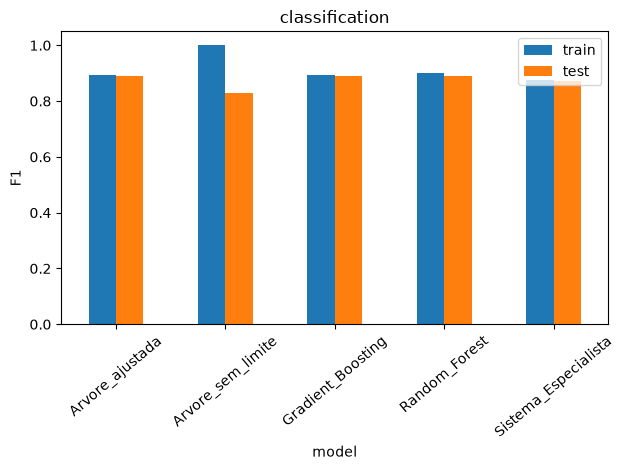

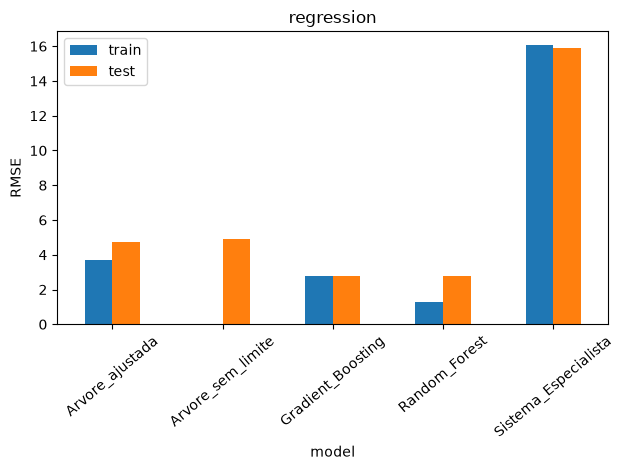

In [3]:
g=pd.read_csv(TAB/'generalization.csv')
display(g.sort_values(['task','model']).round(4))
for task,d in g.groupby('task'):
    ax=d.plot(x='model',y=['train','test'],kind='bar',title=task,rot=40)
    ax.set_ylabel('F1' if task=='classification' else 'RMSE');plt.tight_layout();plt.show()

## Validação cruzada sobre o treinamento
Regressão usa neg_root_mean_squared_error (valores negativos no scikit-learn), o sinal é invertido para apresentar RMSE positivo. Classificação usa F1 da classe Placed. O sistema especialista não passa por nova aprendizagem e sua CV é opcional.

In [4]:
cv=pd.read_csv(TAB/'cross_validation.csv')
cv['media_interpretavel']=np.where(cv.scoring=='neg_root_mean_squared_error',-cv.cv_mean,cv.cv_mean)
display(cv[['task','model','scoring','media_interpretavel','cv_std']].round(4))

,task,model,scoring,media_interpretavel,cv_std
0,regression,Arvore_sem_limite,neg_root_mean_squared_error,5.0990,0.0517
1,regression,Arvore_ajustada,neg_root_mean_squared_error,4.9214,0.0514
2,regression,Random_Forest,neg_root_mean_squared_error,2.8893,0.0350
3,regression,Gradient_Boosting,neg_root_mean_squared_error,2.7612,0.0589
4,classification,Arvore_sem_limite,f1,0.8284,0.0015
5,classification,Arvore_ajustada,f1,0.8921,0.0024
6,classification,Random_Forest,f1,0.8921,0.0019
7,classification,Gradient_Boosting,f1,0.8931,0.0024


## Evidências de sobreajuste
A árvore sem restrição tende a se ajustar excessivamente ao treinamento, a diferença treino-teste permite examinar esse comportamento. Gaps menores com bom teste apontam melhor generalização, mas não demonstram ausência de viés.

In [5]:
for task in ['regression','classification']:
    r=g[(g.task==task)&(g.model=='Arvore_sem_limite')].iloc[0]
    print(f"{task}: treino={r['train']:.4f}, teste={r['test']:.4f}, gap={r['gap_train_minus_test']:.4f}")

regression: treino=0.0000, teste=4.9101, gap=-4.9101
classification: treino=1.0000, teste=0.8278, gap=0.1722


## Limitações
Uma única divisão externa 80/20 fornece apenas uma estimativa pontual de teste. Além disso, a validação cruzada registrada depois da escolha dos melhores hiperparâmetros compartilha o mesmo conjunto de treino da busca e não é nested CV.